# Chalet

Forecast for now, estimated new snow and sunshine for the next 48 h, a daily outlook, and the SLF avalanche bulletin (danger level, main problem, aspects, altitude).

Snowfall is not a published parameter: it is estimated from forecast precipitation and the zero-degree level (rain→snow ramp 500–100 m below it), at ~1 cm of snow per mm of water.

Data: MeteoSwiss local forecast (OGD); avalanche bulletin © SLF.

In [1]:
import json
import localforecast as lf
import screens

In [2]:
# Find point ids: search by town, station abbreviation or postal code
lf.find_point("St-Luc")

,point_id,point_type_id,point_name,station_abbr,postal_code,point_type_en,point_height_masl
2869,396122,2,St-Luc,NaN,3961.0,Postal code center,1658.0


In [3]:
# SLF warning regions — pick the one containing the chalet
{k: v for k, v in lf.slf_regions().items() if "Anniviers" in v or "Montana" in v}

{'CH-4121': 'Montana', 'CH-4124': "Val d'Anniviers"}

In [4]:
# ── Configuration ──────────────────────────────────────────────
POINT = (396122, 2)       # St-Luc, postal code 3961, 1658 m
SLF_REGION = "CH-4124"    # Val d'Anniviers
# Outside the season there is no bulletin; set a winter time to try the layout
SLF_ACTIVE_AT = None      # e.g. "2026-02-15T10:00:00Z"
HOURS, DAYS = 48, 5
# ───────────────────────────────────────────────────────────────

No avalanche bulletin for this region now


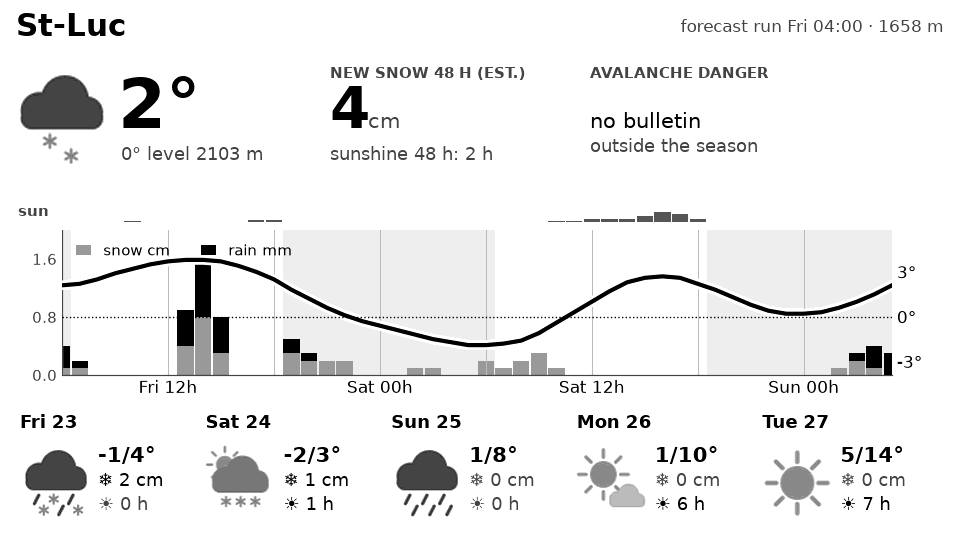

In [5]:
run, data = lf.fetch([POINT], lf.CHALET_PARAMS)
hourly, daily = data[POINT]
bulletin = lf.slf_bulletin(SLF_REGION, active_at=SLF_ACTIVE_AT)
if bulletin is None:
    print("No avalanche bulletin for this region now")
view = lf.chalet_view(run, hourly, daily, lf.point_info(POINT), bulletin, hours=HOURS, days=DAYS)
# LilyGO T5 4.7" e-paper: 960×540, 16 grey levels
img = screens.render(screens.chalet, view)
img

In [6]:
# The payload a display would receive
print(f"{len(json.dumps(view, separators=(',', ':')))} bytes as JSON, "
      f"{len(screens.epd_buffer(img)):,} bytes as a 4-bit frame buffer")
print(json.dumps(view, indent=1)[:1500])

3142 bytes as JSON, 259,200 bytes as a 4-bit frame buffer
{
 "view": "chalet",
 "name": "St-Luc",
 "alt": 1658.0,
 "run": "2026-10-23T04:00:00+02:00",
 "now": {
  "time": "2026-10-23T06:00:00+02:00",
  "temp": 2.1,
  "icon": 116,
  "freezing_m": 2103
 },
 "snow_next_cm": 4.0,
 "hourly": {
  "time": [
   "2026-10-23T06:00:00+02:00",
   "2026-10-23T07:00:00+02:00",
   "2026-10-23T08:00:00+02:00",
   "2026-10-23T09:00:00+02:00",
   "2026-10-23T10:00:00+02:00",
   "2026-10-23T11:00:00+02:00",
   "2026-10-23T12:00:00+02:00",
   "2026-10-23T13:00:00+02:00",
   "2026-10-23T14:00:00+02:00",
   "2026-10-23T15:00:00+02:00",
   "2026-10-23T16:00:00+02:00",
   "2026-10-23T17:00:00+02:00",
   "2026-10-23T18:00:00+02:00",
   "2026-10-23T19:00:00+02:00",
   "2026-10-23T20:00:00+02:00",
   "2026-10-23T21:00:00+02:00",
   "2026-10-23T22:00:00+02:00",
   "2026-10-23T23:00:00+02:00",
   "2026-10-24T00:00:00+02:00",
   "2026-10-24T01:00:00+02:00",
   "2026-10-24T02:00:00+02:00",
   "2026-10-24T03:00:00+02